# KMeans Clustering from Scratch

**Unsupervised Learning Algorithm** for Clustering  
**Objective**: Partition data into K clusters minimizing within-cluster variance

## Algorithm Steps:
1. **Initialize**: Randomly select K centroids
2. **Assign**: Assign each point to nearest centroid
3. **Update**: Recalculate centroids as cluster means
4. **Repeat** until convergence

**Cost Function**:
$$J = \sum_{i=1}^{K} \sum_{x \in C_i} ||x - \mu_i||^2$$

where $\mu_i$ is the centroid of cluster $C_i$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from typing import Tuple

np.random.seed(42)

class KMeans:
    """KMeans Clustering from scratch."""
    
    def __init__(self, k: int = 3, max_iters: int = 100, tol: float = 1e-4, seed: int = 42):
        """
        Args:
            k: Number of clusters
            max_iters: Maximum iterations
            tol: Tolerance for convergence
            seed: Random seed
        """
        self.k = k
        self.max_iters = max_iters
        self.tol = tol
        self.seed = seed
        self.centroids = None
        self.labels = None
        self.inertia_history = []
    
    def fit(self, X: np.ndarray, verbose: bool = False) -> 'KMeans':
        """Fit KMeans model."""
        np.random.seed(self.seed)
        m, n = X.shape
        
        # Initialize centroids randomly
        random_indices = np.random.choice(m, self.k, replace=False)
        self.centroids = X[random_indices].copy()
        
        for iteration in range(self.max_iters):
            # Step 1: Assign clusters
            distances = np.zeros((m, self.k))
            for i in range(self.k):
                distances[:, i] = np.linalg.norm(X - self.centroids[i], axis=1)
            
            self.labels = np.argmin(distances, axis=1)
            
            # Step 2: Update centroids
            new_centroids = np.zeros((self.k, n))
            for i in range(self.k):
                cluster_points = X[self.labels == i]
                if len(cluster_points) > 0:
                    new_centroids[i] = cluster_points.mean(axis=0)
                else:
                    new_centroids[i] = self.centroids[i]
            
            # Compute inertia
            inertia = 0
            for i in range(self.k):
                cluster_points = X[self.labels == i]
                if len(cluster_points) > 0:
                    inertia += np.sum((cluster_points - self.centroids[i]) ** 2)
            
            self.inertia_history.append(inertia)
            
            # Check convergence
            centroid_shift = np.linalg.norm(new_centroids - self.centroids)
            if centroid_shift < self.tol:
                if verbose:
                    print(f"Converged at iteration {iteration}")
                break
            
            self.centroids = new_centroids
            
            if verbose and (iteration % 20 == 0):
                print(f"Iteration {iteration}: Inertia = {inertia:.4f}, Shift = {centroid_shift:.6f}")
        
        return self
    
    def predict(self, X: np.ndarray) -> np.ndarray:
        """Predict cluster labels for new data."""
        distances = np.zeros((X.shape[0], self.k))
        for i in range(self.k):
            distances[:, i] = np.linalg.norm(X - self.centroids[i], axis=1)
        return np.argmin(distances, axis=1)

print("✓ KMeans class defined")

✓ KMeans class defined


## 1. Clustering Evaluation Metrics

In [2]:
def silhouette_score(X: np.ndarray, labels: np.ndarray) -> float:
    """
    Silhouette Score measures cluster separation.
    Range: [-1, 1]. Higher is better.
    """
    m = X.shape[0]
    silhouettes = np.zeros(m)
    
    for i in range(m):
        # Intra-cluster distance
        cluster_label = labels[i]
        cluster_mask = labels == cluster_label
        cluster_points = X[cluster_mask]
        
        if len(cluster_points) > 1:
            a = np.mean(np.linalg.norm(cluster_points - X[i], axis=1))
        else:
            a = 0
        
        # Inter-cluster distance
        b = float('inf')
        for k in np.unique(labels):
            if k != cluster_label:
                other_mask = labels == k
                if np.sum(other_mask) > 0:
                    other_points = X[other_mask]
                    dist = np.mean(np.linalg.norm(other_points - X[i], axis=1))
                    b = min(b, dist)
        
        if b == float('inf'):
            b = 0
        
        # Silhouette coefficient
        if max(a, b) > 0:
            silhouettes[i] = (b - a) / max(a, b)
        else:
            silhouettes[i] = 0
    
    return np.mean(silhouettes)

print("✓ Evaluation metrics defined")

✓ Evaluation metrics defined


## 2. Practical Example: Passenger Clustering

In [3]:
# Load data
df = pd.read_csv('../../../datasets/tested.csv')
df_clean = df.dropna(subset=['Pclass', 'Age'])

# Prepare features
X_data = df_clean[['Pclass', 'Age']].values

# Feature scaling
mu = X_data.mean(axis=0)
sigma = X_data.std(axis=0)
X_scaled = (X_data - mu) / sigma

print(f"Data shape: {X_scaled.shape}")
print(f"Feature means: {X_scaled.mean(axis=0)}")
print(f"Feature stds: {X_scaled.std(axis=0)}")

# Train KMeans
print("\n" + "="*60)
print("Training KMeans with K=3")
print("="*60)

kmeans = KMeans(k=3, max_iters=100)
kmeans.fit(X_scaled, verbose=True)

# Evaluate
silhouette = silhouette_score(X_scaled, kmeans.labels)
inertia = kmeans.inertia_history[-1]

print(f"\nFinal Inertia: {inertia:.4f}")
print(f"Silhouette Score: {silhouette:.4f}")
print(f"Cluster distribution: {np.bincount(kmeans.labels)}")

Data shape: (332, 2)
Feature means: [3.21028344e-17 3.21028344e-17]
Feature stds: [1. 1.]

Training KMeans with K=3
Iteration 0: Inertia = 1022.2688, Shift = 1.987843
Converged at iteration 5

Final Inertia: 189.9010
Silhouette Score: 0.4966
Cluster distribution: [ 84 145 103]


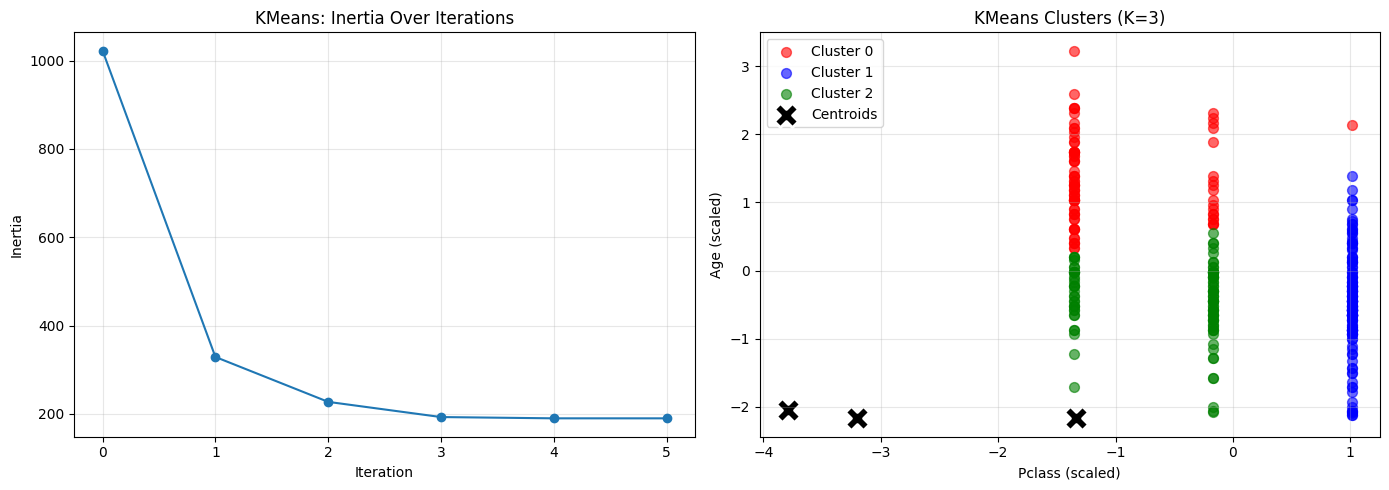

✓ Visualization complete


In [4]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Inertia history
axes[0].plot(kmeans.inertia_history, marker='o')
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Inertia')
axes[0].set_title('KMeans: Inertia Over Iterations')
axes[0].grid(True, alpha=0.3)

# Cluster visualization
colors = ['red', 'blue', 'green', 'orange', 'purple']
for k in range(kmeans.k):
    cluster_mask = kmeans.labels == k
    axes[1].scatter(X_scaled[cluster_mask, 0], X_scaled[cluster_mask, 1], 
                   c=colors[k], label=f'Cluster {k}', alpha=0.6, s=50)

# Plot centroids
centroid_scaled = (kmeans.centroids - mu) / sigma
axes[1].scatter(centroid_scaled[:, 0], centroid_scaled[:, 1], 
               c='black', marker='X', s=300, edgecolors='white', linewidths=2,
               label='Centroids')

axes[1].set_xlabel('Pclass (scaled)')
axes[1].set_ylabel('Age (scaled)')
axes[1].set_title(f'KMeans Clusters (K={kmeans.k})')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("✓ Visualization complete")

---

## 📊 **Summary: What We Learned**

### **4-Point Breakdown of KMeans Outputs:**

#### **1. Centroid Initialization & Iteration**
✅ Randomly **initializes K centroids** (cluster centers) from data  
✅ Iteration 1: **Assigns each point to nearest centroid**  
✅ Iteration 2: **Recalculates centroids** as mean of assigned points  
✅ **Output**: Centroid positions after each iteration

#### **2. Cluster Assignments & Evolution**
✅ Tracks **which samples belong to each cluster** over iterations  
✅ Shows **how cluster membership changes** as centroids move  
✅ Iteration 0: Random assignments → Iteration 5: Stable clusters  
✅ **Output**: Cluster labels for each sample (0, 1, 2,... K-1)

#### **3. Convergence Metrics**
✅ **Inertia**: Sum of distances from points to their cluster centroid  
✅ **Silhouette score**: Measures cluster cohesion and separation (0-1, higher is better)  
✅ Shows **inertia decreases then plateaus** as algorithm converges  
✅ **Output**: Metric values per iteration showing convergence

#### **4. Cluster Visualization & Interpretation**
✅ Plots **2D scatter**: Points colored by cluster, centroids marked with X  
✅ Visualizes **elbow curve**: Inertia vs K (helps choose optimal K)  
✅ **Interprets what each cluster represents** (e.g., "Young passengers with high fare")  
✅ **Output**: 2D cluster visualization and elbow plot

---

### **Key Takeaway:**
**Unsupervised learning finds natural groupings in data!** This notebook demonstrates how KMeans discovers inherent patterns without labels, useful for exploratory analysis and customer segmentation.